# Survey analysis: AI use in academic research

This notebook analyzes the uploaded survey CSV and produces tables, charts, and CSV exports for:

1. **Most-used AI models/tools** (from the free-text tool question).
2. **Where/how AI is used in academic-paper work** (multi-select academic-reading tasks, difficult paper sections, and paper types needing AI).
3. **Likert-scale responses** (response distributions, mean/median/standard deviation, and scale-level summaries).

> **Important:** The dataset currently contains only 11 participants. Treat percentages and averages as descriptive results, not population-level conclusions. The AI-tool question is free text, so the model-name extraction uses an editable alias dictionary; inspect and update it if participants use unfamiliar names or abbreviations.


## 1. Setup and load the data

Put `cleaned_data.csv` in the same folder as this notebook, or change `CSV_PATH` below.


In [1]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# If the CSV is beside this notebook, this should work as-is.
CSV_PATH = Path("cleaned_data.csv")

# If needed, replace with the full path, e.g.:
# CSV_PATH = Path("/content/drive/MyDrive/cleaned_data.csv")

df = pd.read_csv(CSV_PATH)
print(f"Rows (responses): {len(df)}")
print(f"Columns: {len(df.columns)}")
display(df.head())


Rows (responses): 11
Columns: 83


,8.Age / 年龄,9.Gender / 性别,9.Gender / 性别[选项填空],10.Student status / 学生身份,11.If international， what country are you from? / 若为国际学生，您来自哪个国家,12.Current level of study / 当前学习阶段,13.Department or programme / 所在院系或专业,14.Are you currently working on a thesis， dissertation， or final-year project? / 您目前是否在撰写学位论文或毕业项目？,15.How many academic papers have you read for your thesis project so far? / 到目前为止，您为学位论文阅读了多少篇学术论文？,16.How would you describe your confidence in reading academic papers without AI tools? / 不使用AI工具时，您阅读学术论文的信心如何?,...,52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？:Papers with complex methods / 方法复杂的论文,52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？:Papers with unclear writing / 写作不清晰的论文,52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？:Papers in another language / 其他语言的论文,52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？:____,52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？:____[选项填空],52.Which types of papers do you feel need AI assistance the most? / 您觉得哪些类型的论文最需要AI辅助？: None / 都没有,53.Has AI assistance changed how you select which papers to read deeply? Please explain. / AI辅助是否改变了您选择精读哪些论文的方式？请说明,54.Has AI assistance changed how you connect different papers together (e.g.， comparing findings， identifying gaps， building a literature map)? If yes， explain how. / AI辅助是否改变了您将不同论文联系起来的方式（如比较发现、识别空白、构建文献地图）？如有，请说明。,55.When reading papers in English (your second language， if applicable)， do you rely on AI more than when reading in your first language? / 阅读英文论文（如为您的第二语言）时，您是否比阅读母语论文时更依赖AI？,Participant ID
0,D.29+,D.Prefer not to say / 不愿透露,NaN,B.Local student / 本地学生,NaN,B.PhD / 博士,CIAA,B.No / 否,E.More than 15 / 15篇以上,A.Very low / 非常低,...,C.Papers with complex methods / 方法复杂的论文,D.Papers with unclear writing / 写作不清晰的论文,E.Papers in another language / 其他语言的论文,NaN,NaN,NaN,可以以聊天的形式不断给出query,有的，AI可以直接生成综述,A.Yes， much more / 是，依赖得多很多,11
1,B.21 - 24,A.Female / 女,NaN,B.Local student / 本地学生,NaN,A.Master's / 硕士,hci,B.No / 否,A.None / 无,B.Low / 低,...,C.Papers with complex methods / 方法复杂的论文,D.Papers with unclear writing / 写作不清晰的论文,E.Papers in another language / 其他语言的论文,NaN,NaN,NaN,是，精度范围更准确,是，论文间关联更清晰,A.Yes， much more / 是，依赖得多很多,10
2,B.21 - 24,B.Male / 男,NaN,B.Local student / 本地学生,NaN,A.Master's / 硕士,多媒体通信,A.Yes / 是,C.4 - 8,C.Moderate / 中等,...,NaN,D.Papers with unclear writing / 写作不清晰的论文,NaN,NaN,NaN,NaN,改变了,是的,C.About the same / 差不多,9
3,C.25 - 28,A.Female / 女,NaN,B.Local student / 本地学生,NaN,A.Master's / 硕士,AIAT,B.No / 否,B.1 - 3,A.Very low / 非常低,...,C.Papers with complex methods / 方法复杂的论文,D.Papers with unclear writing / 写作不清晰的论文,E.Papers in another language / 其他语言的论文,NaN,NaN,NaN,我没咋读过论文！,是的，更方便，可以多篇联系,A.Yes， much more / 是，依赖得多很多,8
4,B.21 - 24,B.Male / 男,NaN,A.International student / 国际学生,Indonesia,A.Master's / 硕士,Financial Computing,A.Yes / 是,E.More than 15 / 15篇以上,D.High / 高,...,C.Papers with complex methods / 方法复杂的论文,NaN,NaN,NaN,NaN,NaN,Not much.,Yes， they can help me find the main difference...,A.Yes， much more / 是，依赖得多很多,7


## 2. Identify survey columns

The survey headers are long and bilingual. The helper below finds columns by question number and/or keywords, so you do not need to type the full headers.


In [2]:
def find_cols(*patterns):
    """Return columns whose header contains every supplied pattern (case-insensitive)."""
    found = []
    for col in df.columns:
        header = str(col).casefold()
        if all(p.casefold() in header for p in patterns):
            found.append(col)
    return found

def first_col(*patterns):
    matches = find_cols(*patterns)
    if not matches:
        raise KeyError(f"No column found for patterns: {patterns}")
    return matches[0]

# Main free-text AI tool/model question
tool_col = first_col("19.", "which ai tools")

# Question 32: actions/tasks participants ask AI to perform when reading papers
task_cols = find_cols("32.", "what do you usually ask it to do")

# Question 48: paper parts participants find difficult without AI
difficulty_cols = find_cols("48.", "which parts do you find most difficult")

# Question 52: paper types participants think need AI assistance
paper_type_cols = find_cols("52.", "which types of papers")

# Likert / ordinal items. Q21–27, Q37–44, Q45, Q49–51.
likert_cols = (
    find_cols("21.") + find_cols("22.") + find_cols("23.") +
    find_cols("24.") + find_cols("25.") + find_cols("26.") +
    find_cols("27.") +
    [c for c in df.columns if re.match(r"^(37|38|39|40|41|42|43|44)\.", str(c).strip())] +
    find_cols("45.") + find_cols("49.") + find_cols("50.") + find_cols("51.")
)

print("AI tools column:", tool_col)
print("\nAI reading task columns:")
for c in task_cols: print("-", c.split(":")[-1].strip())
print("\nDifficult paper-section columns:")
for c in difficulty_cols: print("-", c.split(":")[-1].strip())
print("\nPaper-type columns:")
for c in paper_type_cols: print("-", c.split(":")[-1].strip())
print(f"\nLikert/ordinal items found: {len(likert_cols)}")


AI tools column: 19.Which AI tools have you used for academic reading， summarizing， or writing? Please list the tools and briefly describe how you use them. / 您使用过哪些AI工具进行学术阅读、总结或写作？请列出工具并简要说明用途。

AI reading task columns:
- Summarize / 总结
- Explain methods / 解释研究方法
- Translate / 翻译
- Compare papers / 比较不同论文
- Identify research gaps / 识别研究空白
- Simplify language / 简化语言
- Define terms / 解释术语
- Extract limitations / 提取研究局限
- ____
- ____[选项填空]

Difficult paper-section columns:
- Abstract / 摘要
- Research gap / 研究空白
- Methodology / 研究方法
- Results / 研究结果
- Discussion / 讨论
- References / 参考文献
- Technical terms / 专业术语
- ____
- ____[选项填空]
- None / 都没有

Paper-type columns:
- Highly technical papers / 技术性很强的论文
- Papers in a new field / 新领域的论文
- Papers with complex methods / 方法复杂的论文
- Papers with unclear writing / 写作不清晰的论文
- Papers in another language / 其他语言的论文
- ____
- ____[选项填空]
- None / 都没有

Likert/ordinal items found: 19


## 3. Most-used AI models/tools

The tool question is open-ended. The script counts recognizable model/tool names using aliases (for example, `GPT` and `ChatGPT` are grouped as **ChatGPT / GPT**). Each participant is counted at most once per model, even if they mention it more than once.

**Review the alias dictionary** before interpreting the results. Add aliases where needed. Mentions that do not match a known alias are listed separately for manual review.


In [3]:
# Edit/add aliases to match the wording used by your participants.
MODEL_ALIASES = {
    "ChatGPT / GPT": [r"chat\s*gpt", r"gpt", r"openai"],
    "Claude": [r"\bclaude\b", r"anthropic"],
    "Gemini": [r"\bgemini\b", r"google\s*gemini"],
    "Doubao": [r"豆包", r"\bdoubao\b"],
    "DeepSeek": [r"deep\s*seek", r"deepseek", r"\bds\b"],
    "Qwen / Qianwen": [r"qwen", r"千问", r"通义"],
    "Codex": [r"codex"],
    "Harness": [r"harness"],
    "Xipu AI": [r"xipu\s*ai", r"西浦ai", r"西浦\s*ai"],
    "LibAI Portal": [r"libai", r"libai\s*portal"],
}

def normalize_text(value):
    if pd.isna(value):
        return ""
    return unicodedata.normalize("NFKC", str(value)).casefold()

compiled_aliases = {
    model: [re.compile(pattern, flags=re.IGNORECASE) for pattern in patterns]
    for model, patterns in MODEL_ALIASES.items()
}

model_mentions = {model: [] for model in MODEL_ALIASES}
unmatched_responses = []

for idx, response in df[tool_col].items():
    text = normalize_text(response)
    if not text.strip() or text.strip() in {"no response", "nan", "none"}:
        continue

    matched_any = False
    for model, patterns in compiled_aliases.items():
        if any(pattern.search(text) for pattern in patterns):
            model_mentions[model].append(idx)
            matched_any = True

    if not matched_any:
        unmatched_responses.append({"row_index": idx, "response": response})

model_counts = pd.Series(
    {model: len(set(rows)) for model, rows in model_mentions.items()},
    name="Participants"
).sort_values(ascending=False)
model_counts = model_counts[model_counts > 0]

model_summary = model_counts.to_frame()
model_summary["Percent of all participants"] = (
    model_summary["Participants"] / len(df) * 100
).round(1)
model_summary["Percent of tool-question respondents"] = (
    model_summary["Participants"] / df[tool_col].replace(
        ["No response", ""], np.nan
    ).dropna().shape[0] * 100
).round(1)

display(model_summary)
print("Most frequently mentioned model/tool(s):")
if not model_summary.empty:
    top_n = model_summary["Participants"].max()
    print(", ".join(model_summary.index[model_summary["Participants"] == top_n]))
else:
    print("No recognized model names. Review MODEL_ALIASES.")

print("\nUnmatched responses for manual review:")
display(pd.DataFrame(unmatched_responses))


,Participants,Percent of all participants,Percent of tool-question respondents
ChatGPT / GPT,7,63.6,63.6
Doubao,2,18.2,18.2
Claude,1,9.1,9.1
Gemini,1,9.1,9.1
DeepSeek,1,9.1,9.1
Codex,1,9.1,9.1
Xipu AI,1,9.1,9.1
Harness,1,9.1,9.1
LibAI Portal,1,9.1,9.1


Most frequently mentioned model/tool(s):
ChatGPT / GPT

Unmatched responses for manual review:


""


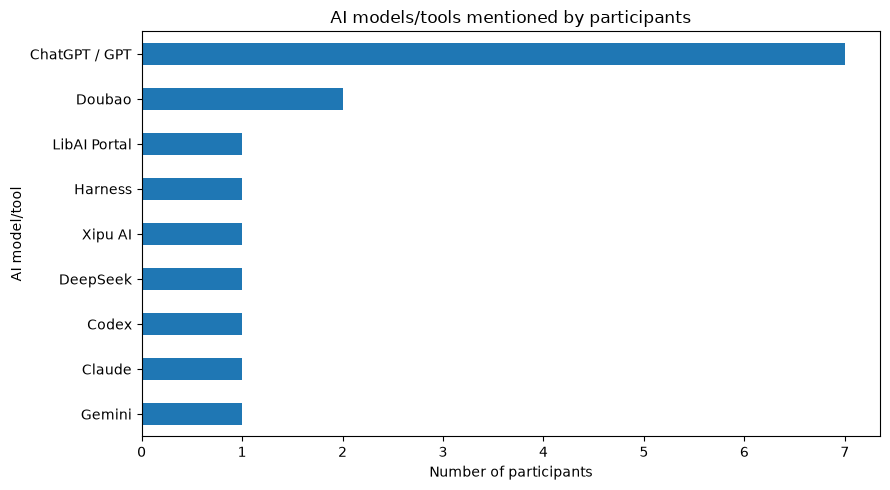

In [4]:
if not model_summary.empty:
    ax = model_summary["Participants"].sort_values().plot(
        kind="barh", figsize=(9, 5), title="AI models/tools mentioned by participants"
    )
    ax.set_xlabel("Number of participants")
    ax.set_ylabel("AI model/tool")
    plt.tight_layout()
    plt.show()


## 4. What participants use AI for when reading research papers

Question 32 appears as one column per selectable task. The notebook counts selected responses and excludes blank / `No response` entries. Percentages use the number of valid respondents to that task question as the denominator; because participants may select multiple tasks, percentages can add up to more than 100%.


,Option,Participants selecting,Percent of all participants,Valid responses in column
1,Explain methods / 解释研究方法,9,81.8,9
0,Summarize / 总结,8,72.7,8
2,Translate / 翻译,7,63.6,7
6,Define terms / 解释术语,6,54.5,6
3,Compare papers / 比较不同论文,3,27.3,3
4,Identify research gaps / 识别研究空白,3,27.3,3
5,Simplify language / 简化语言,3,27.3,3
7,Extract limitations / 提取研究局限,1,9.1,1


C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 25552 (\N{CJK UNIFIED IDEOGRAPH-63D0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 21462 (\N{CJK UNIFIED IDEOGRAPH-53D6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 30740 (\N{CJK UNIFIED IDEOGRAPH-7814}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 31350 (\N{CJK UNIFIED IDEOGRAPH-7A76}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 23616 (\N{CJK UNIFIED IDEOGRAPH-5C40}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\1345373558.py:40: UserWarning: Glyph 38480 (\

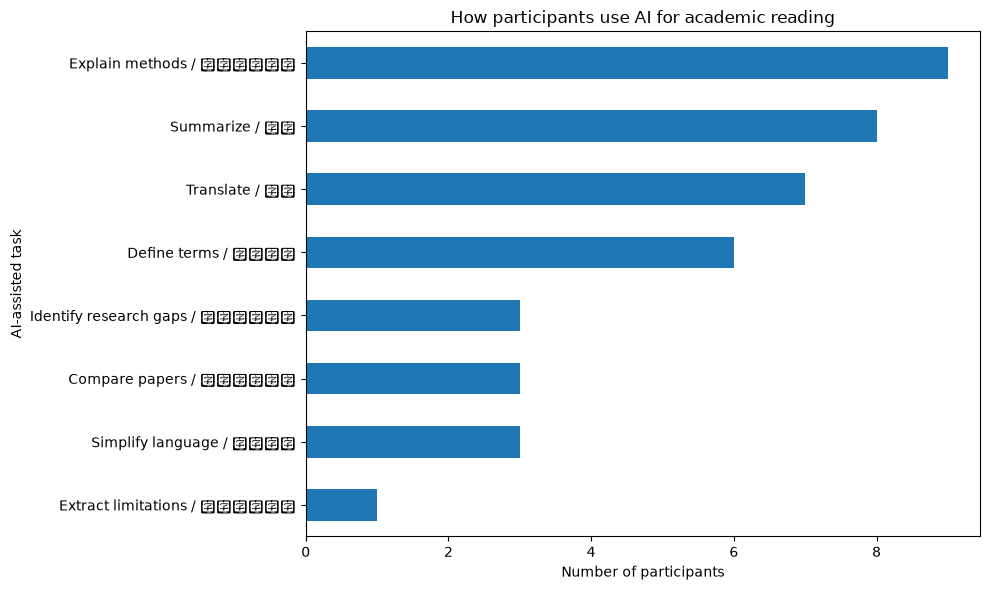

In [5]:
def is_selected(value):
    if pd.isna(value):
        return False
    s = str(value).strip().casefold()
    return s not in {"", "no response", "nan", "none", "not selected"}

def option_label(col):
    # The selectable option is usually after the final colon in the header.
    return str(col).split(":")[-1].strip().replace("[选项填空]", "")

def multiselect_summary(columns):
    rows = []
    for col in columns:
        selected = df[col].apply(is_selected)
        n_selected = int(selected.sum())
        n_answered = int(df[col].notna().sum())
        label = option_label(col)
        # Ignore empty "other" fields and options never selected by anyone.
        if not label or label.strip("_ /") == "" or n_selected == 0:
            continue
        rows.append({
            "Option": label,
            "Participants selecting": n_selected,
            "Percent of all participants": round(n_selected / len(df) * 100, 1) if len(df) else np.nan,
            "Valid responses in column": n_answered
        })
    return pd.DataFrame(rows).sort_values("Participants selecting", ascending=False)

task_summary = multiselect_summary(task_cols)
display(task_summary)

if not task_summary.empty:
    ax = task_summary.sort_values("Participants selecting").plot(
        x="Option", y="Participants selecting", kind="barh",
        legend=False, figsize=(10, 6),
        title="How participants use AI for academic reading"
    )
    ax.set_xlabel("Number of participants")
    ax.set_ylabel("AI-assisted task")
    plt.tight_layout()
    plt.show()


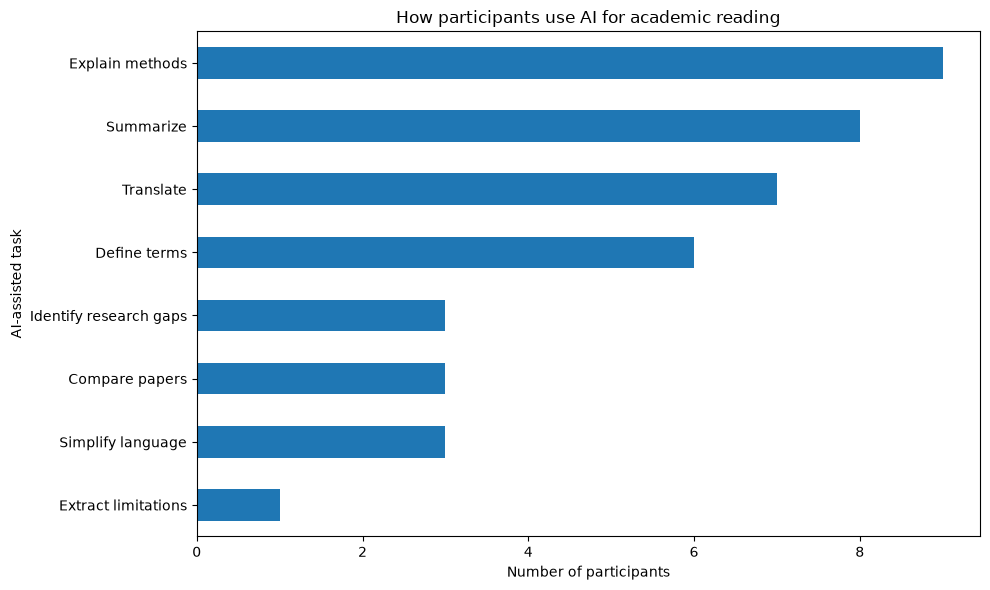

In [6]:
if not task_summary.empty:
    chart_data = task_summary.copy()
    chart_data["Option"] = chart_data["Option"].str.split("/", n=1).str[0].str.strip()

    ax = chart_data.sort_values("Participants selecting").plot(
        x="Option",
        y="Participants selecting",
        kind="barh",
        legend=False,
        figsize=(10, 6),
        title="How participants use AI for academic reading"
    )
    ax.set_xlabel("Number of participants")
    ax.set_ylabel("AI-assisted task")
    plt.tight_layout()
    plt.show()

### Other paper-related results: difficult sections and paper types

These provide context about which parts of papers participants find difficult without AI (Question 48) and which types of papers they believe need AI most (Question 52).


Paper sections participants find most difficult without AI (Q48):


,Option,Participants selecting,Percent of all participants,Valid responses in column
2,Methodology / 研究方法,6,54.5,6
5,Technical terms / 专业术语,5,45.5,5
3,Discussion / 讨论,4,36.4,4
1,Research gap / 研究空白,3,27.3,3
0,Abstract / 摘要,1,9.1,1
4,References / 参考文献,1,9.1,1
6,None / 都没有,1,9.1,1


Types of papers participants think need AI assistance most (Q52):


,Option,Participants selecting,Percent of all participants,Valid responses in column
0,Highly technical papers / 技术性很强的论文,8,72.7,8
2,Papers with complex methods / 方法复杂的论文,8,72.7,8
1,Papers in a new field / 新领域的论文,6,54.5,6
3,Papers with unclear writing / 写作不清晰的论文,6,54.5,6
4,Papers in another language / 其他语言的论文,5,45.5,5


C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 32771 (\N{CJK UNIFIED IDEOGRAPH-8003}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 29486 (\N{CJK UNIFIED IDEOGRAPH-732E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 37117 (\N{CJK UNIFIED IDEOGRAPH-90FD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 27809 (\

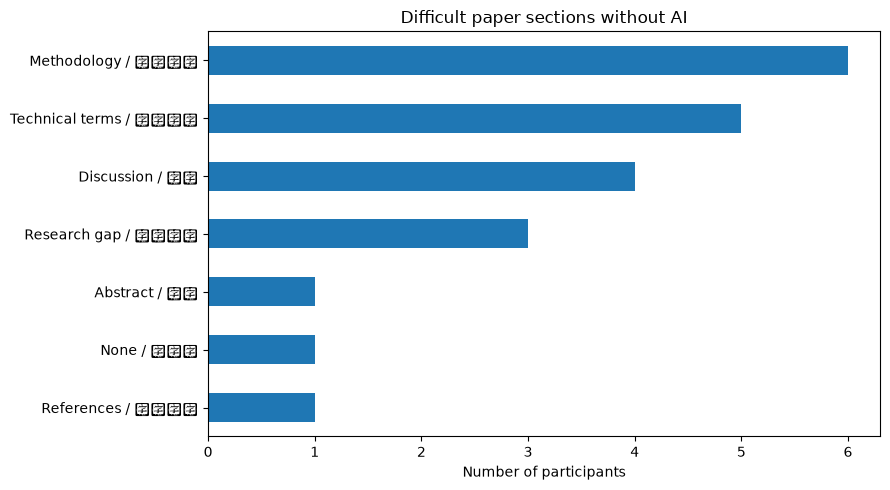

C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 20854 (\N{CJK UNIFIED IDEOGRAPH-5176}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 20182 (\N{CJK UNIFIED IDEOGRAPH-4ED6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 35821 (\N{CJK UNIFIED IDEOGRAPH-8BED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 35328 (\N{CJK UNIFIED IDEOGRAPH-8A00}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\4010548240.py:21: UserWarning: Glyph 35770 (\

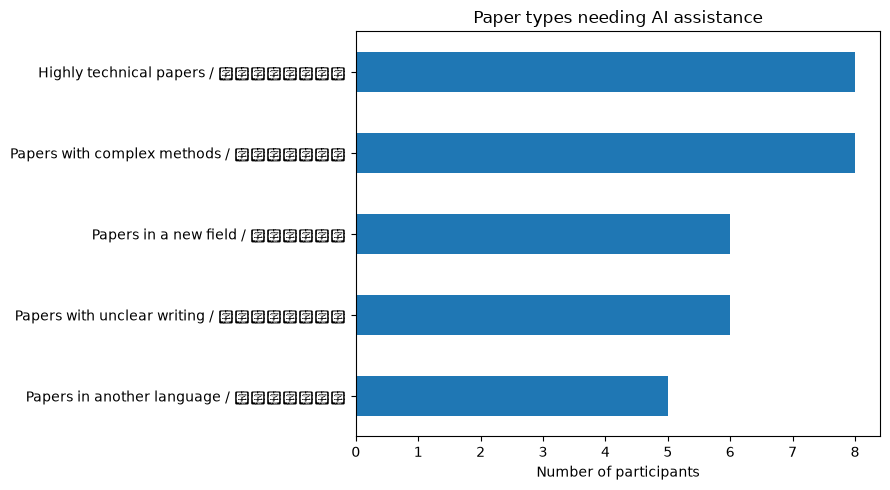

In [7]:
difficulty_summary = multiselect_summary(difficulty_cols)
paper_type_summary = multiselect_summary(paper_type_cols)

print("Paper sections participants find most difficult without AI (Q48):")
display(difficulty_summary)

print("Types of papers participants think need AI assistance most (Q52):")
display(paper_type_summary)

for title, summary in [
    ("Difficult paper sections without AI", difficulty_summary),
    ("Paper types needing AI assistance", paper_type_summary)
]:
    if not summary.empty:
        ax = summary.sort_values("Participants selecting").plot(
            x="Option", y="Participants selecting", kind="barh",
            legend=False, figsize=(9, 5), title=title
        )
        ax.set_xlabel("Number of participants")
        ax.set_ylabel("")
        plt.tight_layout()
        plt.show()


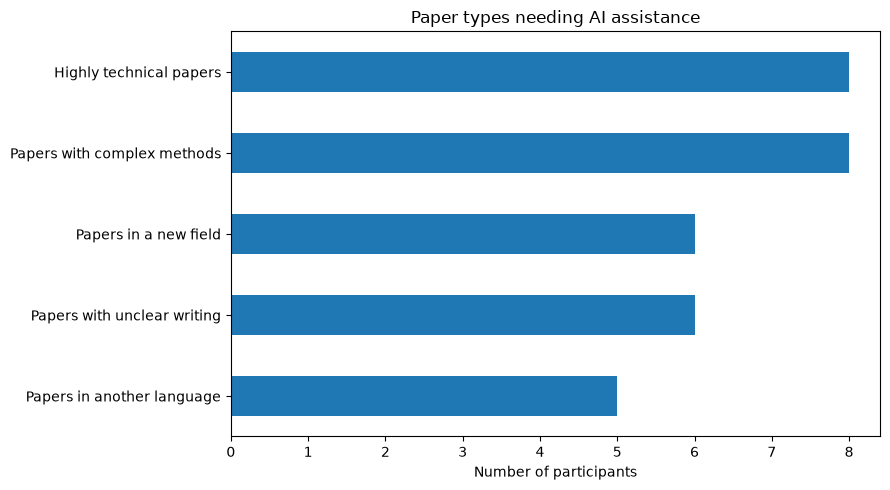

In [8]:
if not paper_type_summary.empty:
    chart_data = paper_type_summary.copy()
    chart_data["Option"] = chart_data["Option"].str.split("/", n=1).str[0].str.strip()

    ax = chart_data.sort_values("Participants selecting").plot(
        x="Option",
        y="Participants selecting",
        kind="barh",
        legend=False,
        figsize=(9, 5),
        title="Paper types needing AI assistance"
    )
    ax.set_xlabel("Number of participants")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

## 5. Likert-scale analysis

This section handles two common formats in the questionnaire:

- Numeric responses such as `1`–`5`.
- Labeled frequency responses such as `A.Never`, `B.Rarely`, ..., `E.Almost every time`.

The labels are mapped to their ordinal positions (A=1 through E=5). The notebook reports response distributions and descriptive statistics. For interpretation, remember that Likert items are ordinal; frequencies and medians are especially useful. Means are included as commonly used descriptive summaries.

**Reverse-coded item:** Question 50 is negatively worded (“AI assistance has weakened my independent understanding”). Its raw responses are shown as recorded. An optional reverse score (`6 - response`) is also calculated so that higher values consistently indicate a more positive perception when combined with Question 49. Do not combine items into a scale unless the items are theoretically appropriate and reliability has been checked.


In [22]:
import re
import re

def clean_col_name(name):
    s = str(name).strip()
    # Keep only the part before the first "/" or "\", then trim.
    s = re.split(r"[/\\]", s, maxsplit=1)[0].strip()
    # Drop a leading item number like "40." / "40)" / "40、" / "40 -" etc.
    s = re.sub(r"^\s*\d+\s*[.)、\-:]\s*", "", s)
    return s.strip()

# Build a mapping from original column -> cleaned column name.
col_rename = {col: clean_col_name(col) for col in likert_cols}

likert_numeric = pd.DataFrame({
    col: df[col].apply(to_likert_numeric)
    for col in likert_cols
})

# Exclude items that did not parse to any 1–5 response.
likert_numeric = likert_numeric.dropna(axis=1, how="all")

# Rename columns to the stripped English part (only for the ones that survived dropna).
likert_numeric = likert_numeric.rename(columns=col_rename)

likert_stats = pd.DataFrame({
    "N": likert_numeric.count(),
    "Mean": likert_numeric.mean(),
    "Median": likert_numeric.median(),
    "SD": likert_numeric.std(),
    "Min": likert_numeric.min(),
    "Max": likert_numeric.max()
}).round(2)

display(likert_stats)

,N,Mean,Median,SD,Min,Max
I can explain what large language models (e.g.， ChatGPT) can and cannot do.,11,3.55,4.0,1.13,2.0,5.0
I understand that AI-generated content may contain errors， fabricated references， or biased information.,11,4.55,5.0,0.69,3.0,5.0
I know how to write prompts that produce useful results for academic tasks.,11,3.91,4.0,0.70,3.0,5.0
I can judge whether an AI-generated summary accurately reflects the original paper.,11,3.55,4.0,0.93,2.0,5.0
I know XJTLU's rules and policies on the use of AI in academic work.,11,4.18,5.0,1.25,1.0,5.0
I know how to use AI tools in ways that comply with academic integrity standards.,11,4.00,4.0,1.00,2.0,5.0
I can identify when using AI would cross the line into academic misconduct.,11,3.91,4.0,0.83,2.0,5.0
I worry that my use of AI might be considered academic misconduct.,11,2.45,3.0,0.82,1.0,3.0
I feel uncertain about where the line is between acceptable AI assistance and cheating.,11,2.27,2.0,0.90,1.0,4.0
I am afraid of being penalized if my AI use is detected.,11,2.45,2.0,1.13,1.0,5.0


C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\402078555.py:51: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  ax.figure.savefig("likert_distribution.pdf", format="pdf", bbox_inches="tight")
c:\Users\mauka\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


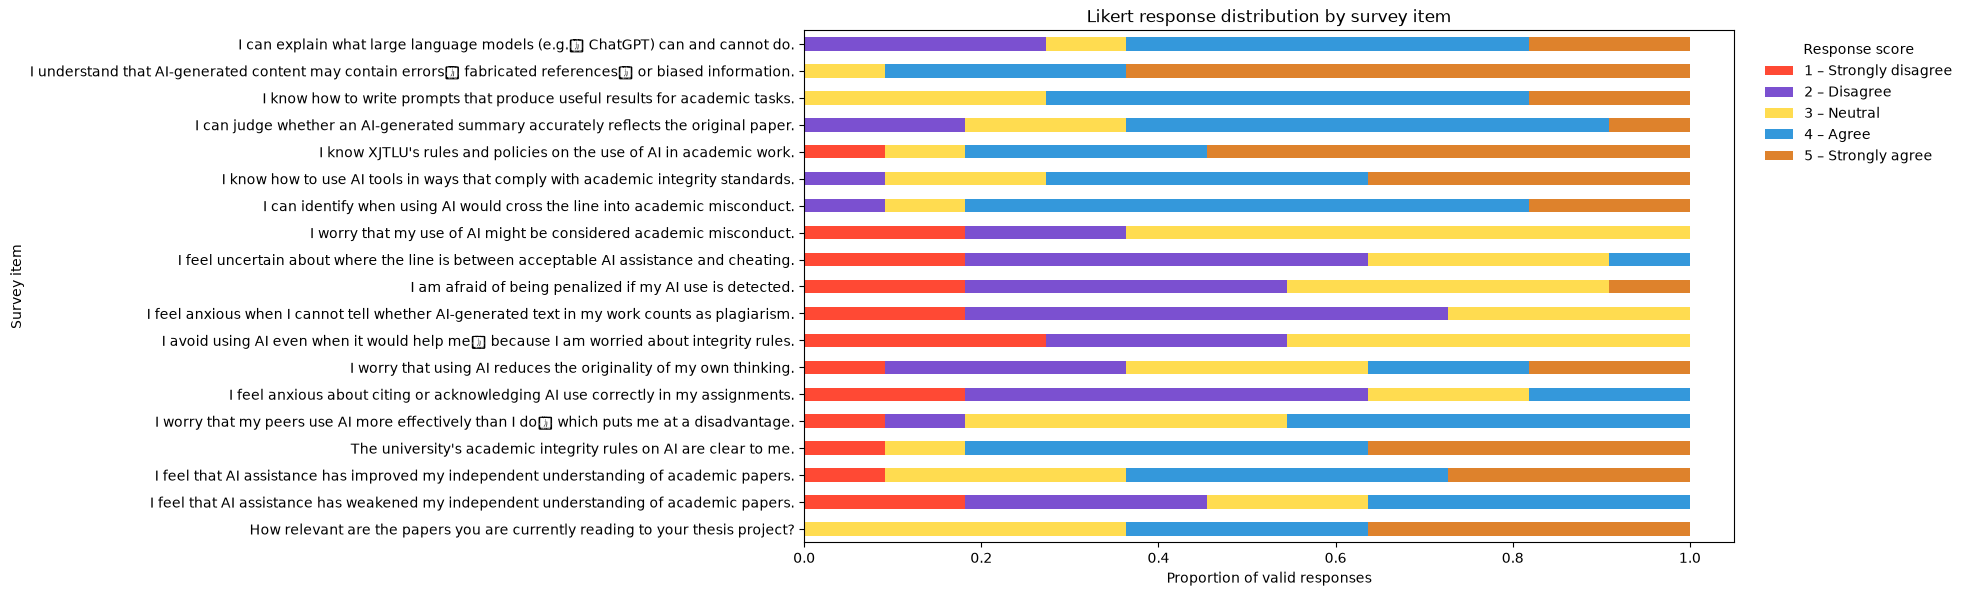

In [32]:
# --- Color configuration -------------------------------------------------
# Option A: diverging scale, red (1) -> neutral (3) -> blue (5).
#   This is the conventional choice for Likert data.
likert_colors = ["#ff4934", "#7b50d0", "#ffdc50", "#3498db", "#de822c"]

# Option B: uncomment to use a sequential/other palette instead.
# import matplotlib.cm as cm
# import matplotlib.colors as mcolors
# cmap = plt.get_cmap("RdYlBu_r")          # or "viridis", "Blues", "coolwarm", ...
# likert_colors = [mcolors.to_hex(cmap(x)) for x in np.linspace(0, 1, 5)]

# Option C: hex codes you pick yourself (1 -> 5 order).
# likert_colors = ["#d73027", "#fc8d59", "#ffffbf", "#91bfdb", "#4575b4"]

# Optional: custom labels for the legend (keeps code numeric, shows words).
likert_labels = ["1 – Strongly disagree", "2 – Disagree", "3 – Neutral",
                 "4 – Agree", "5 – Strongly agree"]

# Heatmap-like stacked bar chart: response proportions for each item.
if not likert_numeric.empty:
    proportions = likert_numeric.apply(
        lambda s: s.value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0),
        axis=0
    ).T
    proportions.columns = ["1", "2", "3", "4", "5"]

    # REVERSE the order so the first item in the DataFrame appears at the top of the chart
    proportions = proportions.iloc[::-1]

    ax = proportions.plot(
        kind="barh", stacked=True,
        figsize=(12, max(6, len(proportions) * 0.35)),
        color=likert_colors,                 # <-- apply the palette here
        title="Likert response distribution by survey item"
    )
    ax.set_xlabel("Proportion of valid responses")
    ax.set_ylabel("Survey item")

    # Legend: pair colors with descriptive labels instead of bare numbers.
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(
        handles, likert_labels,
        title="Response score",
        bbox_to_anchor=(1.02, 1), loc="upper left",
        frameon=False,
    )

    # plt.tight_layout()  # disabled: bbox_inches="tight" in savefig handles clipping

    # Save as a vector image. Use .pdf or .svg — both are vector formats.
    ax.figure.savefig("likert_distribution.pdf", format="pdf", bbox_inches="tight")
    # Alternative: ax.figure.savefig("likert_distribution.svg", format="svg", bbox_inches="tight")

    plt.show()

C:\Users\mauka\AppData\Local\Temp\ipykernel_20996\2938442918.py:39: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  ax.figure.savefig("likert_distribution-2.pdf", format="pdf", bbox_inches="tight")
c:\Users\mauka\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


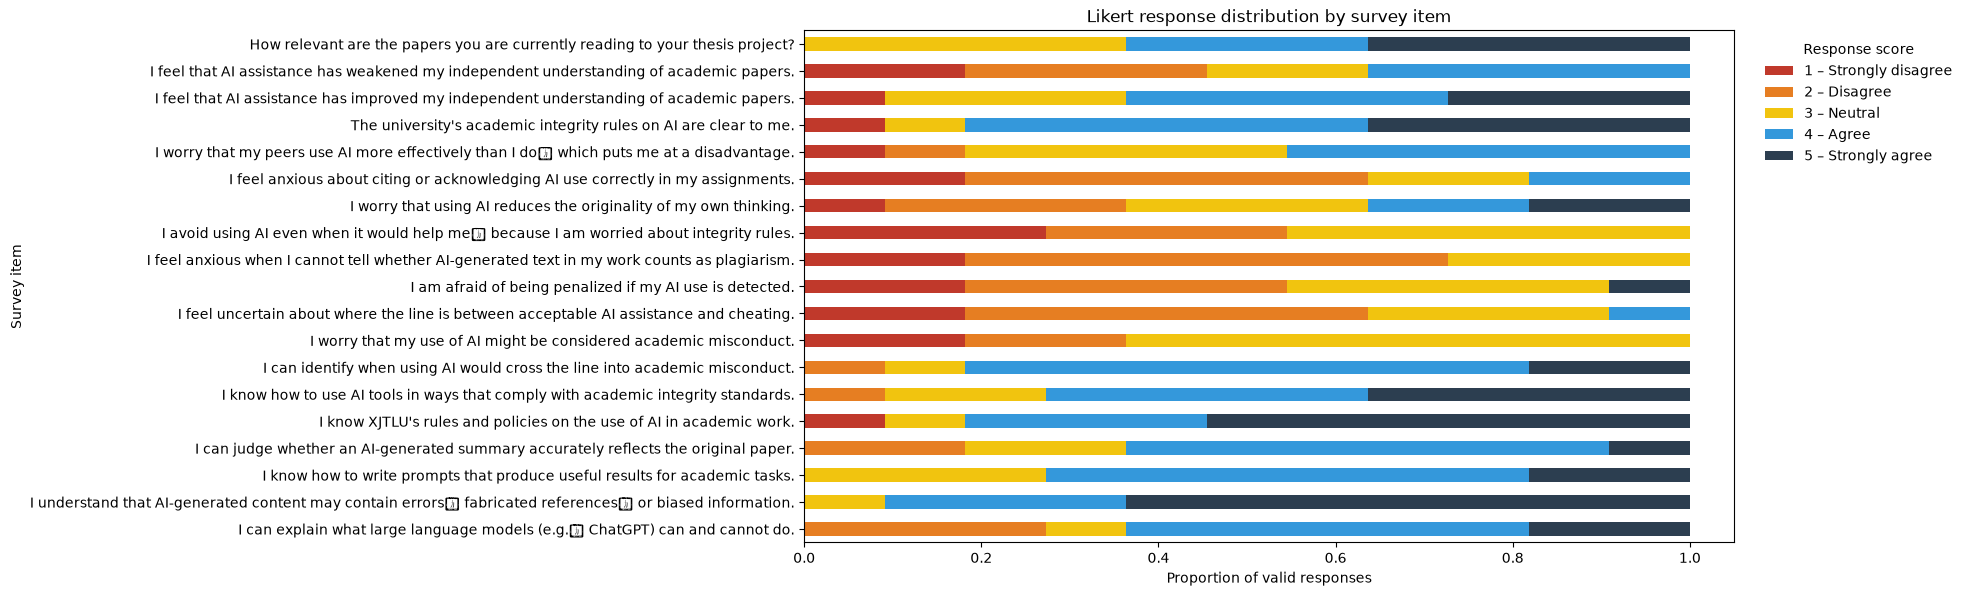

In [33]:
# --- Color configuration -------------------------------------------------
# Option A: diverging scale, red (1) -> neutral (3) -> blue (5).
likert_colors = ["#c0392b", "#e67e22", "#f1c40f", "#3498db", "#2c3e50"]

# Option B: colormap alternative.
# import matplotlib.colors as mcolors
# cmap = plt.get_cmap("RdYlBu_r")
# likert_colors = [mcolors.to_hex(cmap(x)) for x in np.linspace(0, 1, 5)]

likert_labels = ["1 – Strongly disagree", "2 – Disagree", "3 – Neutral",
                 "4 – Agree", "5 – Strongly agree"]

# Heatmap-like stacked bar chart: response proportions for each item.
if not likert_numeric.empty:
    proportions = likert_numeric.apply(
        lambda s: s.value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0),
        axis=0
    ).T
    proportions.columns = ["1", "2", "3", "4", "5"]
    ax = proportions.plot(
        kind="barh", stacked=True,
        figsize=(12, max(6, len(proportions) * 0.35)),
        color=likert_colors,
        title="Likert response distribution by survey item"
    )
    ax.set_xlabel("Proportion of valid responses")
    ax.set_ylabel("Survey item")

    handles, _ = ax.get_legend_handles_labels()
    ax.legend(
        handles, likert_labels,
        title="Response score",
        bbox_to_anchor=(1.02, 1), loc="upper left",
        frameon=False,
    )
    # plt.tight_layout()  # disabled: bbox_inches="tight" in savefig handles clipping

    # Save as a vector image (.pdf or .svg — both vector formats).
    ax.figure.savefig("likert_distribution-2.pdf", format="pdf", bbox_inches="tight")
    # Alternative: ax.figure.savefig("likert_distribution.svg", format="svg", bbox_inches="tight")

    plt.show()  # raster preview only; does not affect the saved vector file

### Optional: reverse-score Question 50

Use this only if you want to align the direction of Question 50 with Question 49. The output is a transformed item, not a new observed response.


In [12]:
q49 = [c for c in likert_numeric.columns if str(c).strip().startswith("49.")]
q50 = [c for c in likert_numeric.columns if str(c).strip().startswith("50.")]

if q49 and q50:
    q49_values = likert_numeric[q49[0]]
    q50_reverse = 6 - likert_numeric[q50[0]]
    paired = pd.DataFrame({
        "Q49: AI improved independent understanding": q49_values,
        "Q50: AI weakened (reverse-scored)": q50_reverse
    })
    display(paired.describe().T.round(2))
    print("Spearman correlation between Q49 and reverse-scored Q50:")
    display(paired.corr(method="spearman").round(3))
else:
    print("Q49 and/or Q50 not found in parsed Likert items.")


,count,mean,std,min,25%,50%,75%,max
Q49: AI improved independent understanding,11.0,3.73,1.19,1.0,3.0,4.0,4.5,5.0
Q50: AI weakened (reverse-scored),11.0,3.27,1.19,2.0,2.0,3.0,4.0,5.0


Spearman correlation between Q49 and reverse-scored Q50:


,Q49: AI improved independent understanding,Q50: AI weakened (reverse-scored)
Q49: AI improved independent understanding,1.000,0.828
Q50: AI weakened (reverse-scored),0.828,1.000


## 6. Optional: overall AI-use frequency

This summarizes how often participants report using AI in academic work overall (Question 20). It is a single ordinal item, not a multi-item Likert scale.


Overall AI-use frequency (Q20):


,Score
count,11.00
mean,3.73
std,1.01
min,2.00
25%,3.50
50%,4.00
75%,4.00
max,5.00


,Participants
Response score,
2,2
3,1
4,6
5,2


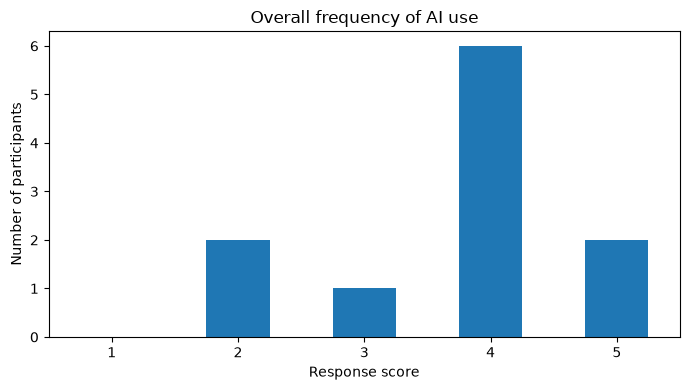

In [13]:
overall_frequency_cols = find_cols("20.", "how often do you use ai tools")
if overall_frequency_cols:
    col = overall_frequency_cols[0]
    vals = pd.to_numeric(df[col], errors="coerce")
    print("Overall AI-use frequency (Q20):")
    display(vals.describe().to_frame("Score").round(2))
    display(vals.value_counts().sort_index().rename_axis("Response score").to_frame("Participants"))

    counts = vals.value_counts().sort_index().reindex([1, 2, 3, 4, 5], fill_value=0)
    counts.plot(
        kind="bar", figsize=(7, 4), title="Overall frequency of AI use"
    )
    plt.xlabel("Response score")
    plt.ylabel("Number of participants")
    plt.xticks(rotation=0)          # keep labels upright
    plt.tight_layout()
    plt.show()

## 7. Export tables for your report

The following cell saves the main summary tables as CSV files in an `analysis_outputs` folder. You can use these tables in your research report or further analysis.


In [14]:
OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

tables_to_export = {
    "ai_model_tool_frequency.csv": model_summary,
    "ai_reading_tasks.csv": task_summary,
    "difficult_paper_sections.csv": difficulty_summary,
    "paper_types_needing_ai.csv": paper_type_summary,
    "likert_descriptive_statistics.csv": likert_stats,
    "likert_response_distribution.csv": likert_distribution,
}

for filename, table in tables_to_export.items():
    table.to_csv(OUTPUT_DIR / filename, encoding="utf-8-sig")

if unmatched_responses:
    pd.DataFrame(unmatched_responses).to_csv(
        OUTPUT_DIR / "unmatched_ai_tool_responses_for_review.csv",
        index=False, encoding="utf-8-sig"
    )

print(f"Exported {len(tables_to_export)} tables to: {OUTPUT_DIR.resolve()}")


Exported 6 tables to: C:\Users\mauka\OneDrive\XJTLU\!sem1\ADS401\ADS401-Group-I-main\survey_method\analysis_outputs


## 8. Suggested reporting language

Use the generated tables to write up the findings. A useful structure is:

- **AI model/tool preference:** report the most frequently mentioned tool, the number of participants, and the percentage of the sample. State that responses came from an open-ended question and that mentions may not represent exclusive use.
- **Purpose of AI use:** rank the Question 32 tasks by participant count and percentage. Note that this was a multiple-response question, so percentages may exceed 100% in total.
- **Paper sections and paper types:** describe the most difficult paper sections and the paper types participants most often said need AI assistance.
- **Likert items:** report response distributions and medians; include means and standard deviations as supplementary descriptive statistics. Avoid causal claims.
- **Sample limitation:** the uploaded file contains a small sample (11 rows), so describe patterns in this dataset rather than generalizing to all students.

Before finalizing, inspect the model alias dictionary and unmatched responses to ensure model names have been grouped correctly.
